In [2]:
print("test")# Assignment 1 – Housing Price Prediction

## Step 1 – Explore and understand the data

The Ames Housing dataset is first explored to understand its structure,
target variable, missing values and potentially useful predictors.

test


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\NTNU\Aktive Emner\Machine Learning\AmesHousing.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (2930, 82)


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [4]:
# Basic information about the dataset
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.info()

Number of rows: 2930
Number of columns: 82
<class 'pandas.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   str    
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   str    
 7   Alley            198 non-null    str    
 8   Lot Shape        2930 non-null   str    
 9   Land Contour     2930 non-null   str    
 10  Utilities        2930 non-null   str    
 11  Lot Config       2930 non-null   str    
 12  Land Slope       2930 non-null   str    
 13  Neighborhood     2930 non-null   str    
 14  Condition 1      2930 non-null   str    
 15  Condition 2      2930 non-null   str    
 16  Bldg Type        2930 non-nu

In [5]:
# Summary statistics for the target variable
df["SalePrice"].describe()

count      2930.000000
mean     180796.060068
std       79886.692357
min       12789.000000
25%      129500.000000
50%      160000.000000
75%      213500.000000
max      755000.000000
Name: SalePrice, dtype: float64

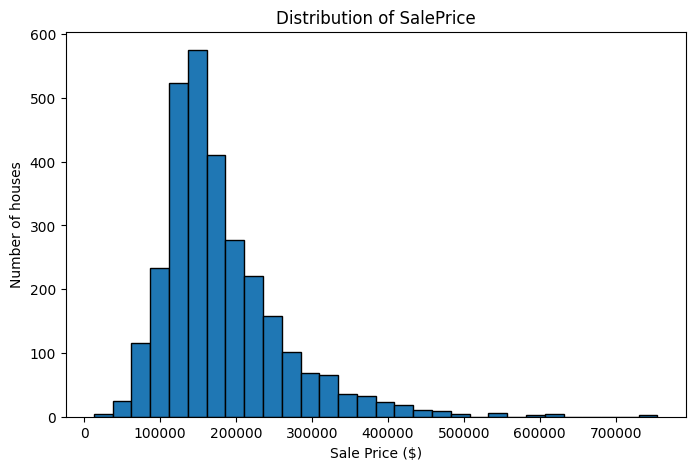

In [6]:
# Distribution of SalePrice
plt.figure(figsize=(8, 5))
plt.hist(df["SalePrice"], bins=30, edgecolor="black")
plt.xlabel("Sale Price ($)")
plt.ylabel("Number of houses")
plt.title("Distribution of SalePrice")
plt.show()

In [8]:
### SalePrice distribution

#The SalePrice distribution is right-skewed. Most houses are concentrated
#in the lower and middle price ranges, while a smaller number of properties
#have very high sale prices. This suggests that the dataset contains some
#unusually expensive properties.

In [9]:
# Missing values
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)

print("Number of columns with missing values:", len(missing))
missing.head(20)

Number of columns with missing values: 27


Pool QC           2917
Misc Feature      2824
Alley             2732
Fence             2358
Mas Vnr Type      1775
Fireplace Qu      1422
Lot Frontage       490
Garage Qual        159
Garage Cond        159
Garage Yr Blt      159
Garage Finish      159
Garage Type        157
Bsmt Exposure       83
BsmtFin Type 2      81
Bsmt Cond           80
Bsmt Qual           80
BsmtFin Type 1      80
Mas Vnr Area        23
Bsmt Full Bath       2
Bsmt Half Bath       2
dtype: int64

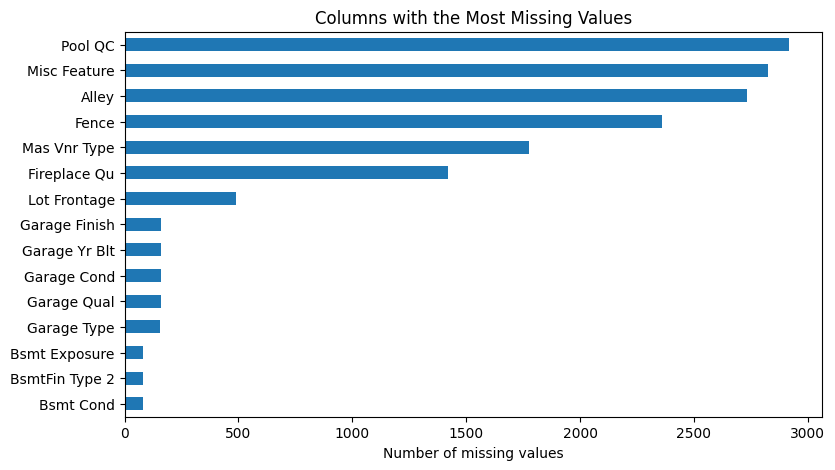

In [10]:
# Visualize columns with the most missing values
plt.figure(figsize=(9, 5))
missing.head(15).sort_values().plot(kind="barh")
plt.xlabel("Number of missing values")
plt.title("Columns with the Most Missing Values")
plt.show()

In [ ]:
### Missing values

Several variables contain missing values. However, missing values do not
always have the same meaning. For some variables, a missing value represents
the absence of a feature, while for others it means that the value was not
recorded.

For example, a missing Fireplace Qu means that the house has no fireplace,
whereas a missing Lot Frontage means that the frontage measurement is
unknown. This distinction will be considered during preprocessing.

In [11]:
# Correlation between numerical variables and SalePrice
numeric_df = df.select_dtypes(include=np.number)

correlations = (
    numeric_df.corr()["SalePrice"]
    .drop("SalePrice")
    .sort_values(ascending=False)
)

correlations.head(10)

Overall Qual      0.799262
Gr Liv Area       0.706780
Garage Cars       0.647877
Garage Area       0.640401
Total Bsmt SF     0.632280
1st Flr SF        0.621676
Year Built        0.558426
Full Bath         0.545604
Year Remod/Add    0.532974
Garage Yr Blt     0.526965
Name: SalePrice, dtype: float64

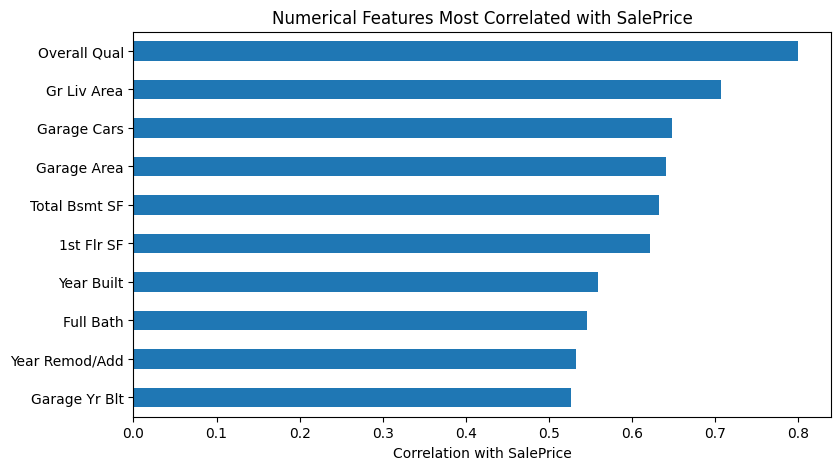

In [12]:
# Strongest numerical correlations with SalePrice
top_features = correlations.head(10)

plt.figure(figsize=(9, 5))
top_features.sort_values().plot(kind="barh")
plt.xlabel("Correlation with SalePrice")
plt.title("Numerical Features Most Correlated with SalePrice")
plt.show()

In [ ]:
### Relationships with SalePrice

The correlation analysis shows that some numerical variables have much
stronger relationships with SalePrice than others. In particular, overall
house quality, living area, garage size and basement/floor area appear to
be useful predictors of house prices.

These relationships will be considered when selecting features for the
prediction models.

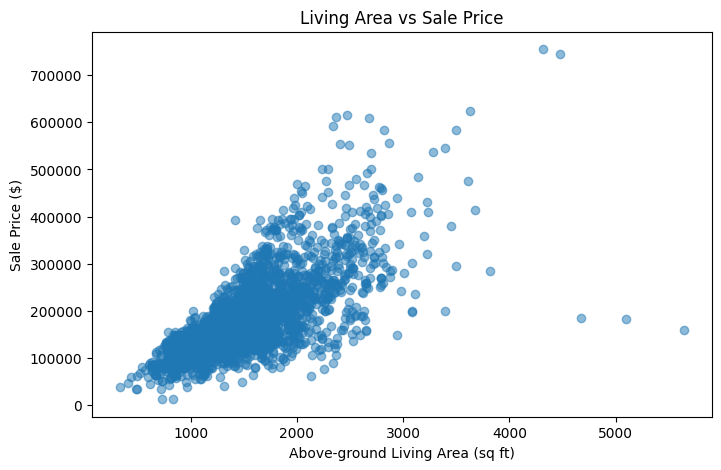

In [13]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Gr Liv Area"], df["SalePrice"], alpha=0.5)
plt.xlabel("Above-ground Living Area (sq ft)")
plt.ylabel("Sale Price ($)")
plt.title("Living Area vs Sale Price")
plt.show()

In [ ]:
There is a clear positive relationship between above-ground living area
and SalePrice. Larger houses generally sell for higher prices. There are
also a few unusual observations, including some very large houses that
sold for relatively low prices.

In [ ]:
## Step 2 – Create training and test data

The dataset is divided into a training set and a test set. The training
data will be used to develop the preprocessing and models, while the test
data will be kept separate until the final evaluation.

In [15]:
from sklearn.model_selection import train_test_split

# Separate predictors and target
X = df.drop(columns=["SalePrice"])
y = df["SalePrice"]

# Split into 80% training data and 20% test data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (2344, 81)
Test set: (586, 81)


In [ ]:
### Train/test split

The data was split into 80% training data and 20% test data. A fixed
random state was used to make the split reproducible.

The test set is kept separate during model development. This is important
because using the test data when making preprocessing or modelling decisions
could give an overly optimistic estimate of model performance. The final
test results therefore provide an evaluation on previously unseen data.

In [16]:
# Remove identifier columns
X_train = X_train.drop(columns=["Order", "PID"])
X_test = X_test.drop(columns=["Order", "PID"])

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Training set: (2344, 79)
Test set: (586, 79)


In [ ]:
The Order and PID columns were removed because they are identifiers rather
than meaningful characteristics of the properties and are therefore not
appropriate predictors of house prices.

In [ ]:
## Step 3 – Prepare the data

The dataset contains both numerical and categorical variables, as well as
missing values. A preprocessing pipeline is created so that preprocessing
is learned only from the training data and then applied consistently to
the test data.

In [18]:
# MS SubClass contains category codes rather than numerical measurements
X_train["MS SubClass"] = X_train["MS SubClass"].astype(str)
X_test["MS SubClass"] = X_test["MS SubClass"].astype(str)

In [ ]:
MS SubClass is stored as numbers in the CSV, but the values represent
categories of house types rather than numerical measurements. It was
therefore treated as a categorical variable.

In [19]:
# Identify numerical and categorical columns
numerical_features = X_train.select_dtypes(include=np.number).columns
categorical_features = X_train.select_dtypes(exclude=np.number).columns

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))

Numerical features: 35
Categorical features: 44


In [20]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numerical preprocessing:
# replace missing values with the median and scale the variables
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing:
# replace missing values with a separate category and one-hot encode
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [21]:
### Preprocessing decisions

Numerical missing values were replaced with the median of the corresponding
training feature. The median was chosen because it is less sensitive to
extreme values than the mean. Numerical features were also standardized.

Categorical missing values were represented by a separate "Missing" category.
This is useful because missing categorical values can sometimes represent
the absence of a feature, such as no fireplace or no pool. Categorical
variables were then converted to numerical form using one-hot encoding.

The preprocessing is fitted only using the training data. The same fitted
preprocessing is later applied to the test data, preventing information from
the test set from influencing model development.

SyntaxError: invalid syntax (2552204522.py, line 3)

In [ ]:
## Step 4 – Feature selection and engineering

Most of the available property features were retained for prediction.
The exploratory analysis showed that variables such as Overall Qual,
Gr Liv Area, garage size and basement/floor area have clear relationships
with SalePrice.

Categorical property characteristics were also retained because variables
such as location, building type and quality categories may contain useful
information that is not captured by numerical correlation alone.

Order and PID were removed earlier because they are identifiers rather than
meaningful property characteristics. MS SubClass was retained but treated
as categorical because its numerical values represent house-type codes.

No additional engineered features were created. The existing dataset already
contains detailed information about property size, quality, age, location
and other characteristics, so the original meaningful features were considered
sufficient for this introductory analysis.

In [ ]:
## Step 5 – Train the models

Three regression models are trained using the same features and preprocessing:
Linear Regression, Decision Tree Regression and Random Forest Regression.

Each model is combined with the preprocessing pipeline so that preprocessing
is fitted using only the training data.

In [22]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Create model pipelines
linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

tree_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeRegressor(random_state=42))
])

forest_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(random_state=42))
])

In [23]:
# Train the three models
linear_model.fit(X_train, y_train)
print("Linear Regression trained.")

tree_model.fit(X_train, y_train)
print("Decision Tree trained.")

forest_model.fit(X_train, y_train)
print("Random Forest trained.")

Linear Regression trained.
Decision Tree trained.
Random Forest trained.


In [ ]:
## Step 6 – Evaluate and interpret the results

The three models are evaluated on the previously unseen test data using
RMSE (Root Mean Squared Error) and R².

Lower RMSE indicates smaller prediction errors, while a higher R² indicates
that the model explains more of the variation in SalePrice.

In [24]:
from sklearn.metrics import mean_squared_error, r2_score

models = {
    "Linear Regression": linear_model,
    "Decision Tree": tree_model,
    "Random Forest": forest_model
}

results = []

for name, model in models.items():
    predictions = model.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "Test RMSE": rmse,
        "Test R²": r2
    })

results_df = pd.DataFrame(results)

results_df

,Model,Test RMSE,Test R²
0,Linear Regression,29157.108351,0.893965
1,Decision Tree,36369.959038,0.835015
2,Random Forest,26001.981535,0.915672


In [25]:
results_display = results_df.copy()

results_display["Test RMSE"] = results_display["Test RMSE"].round(2)
results_display["Test R²"] = results_display["Test R²"].round(3)

results_display

,Model,Test RMSE,Test R²
0,Linear Regression,29157.11,0.894
1,Decision Tree,36369.96,0.835
2,Random Forest,26001.98,0.916


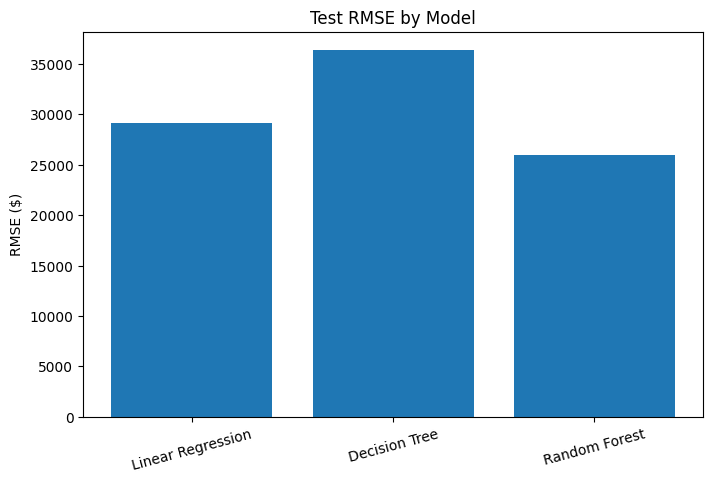

In [26]:
plt.figure(figsize=(8, 5))
plt.bar(results_df["Model"], results_df["Test RMSE"])
plt.ylabel("RMSE ($)")
plt.title("Test RMSE by Model")
plt.xticks(rotation=15)
plt.show()

In [27]:
best_model = results_df.loc[results_df["Test RMSE"].idxmin()]

print("Best model:", best_model["Model"])
print("RMSE:", round(best_model["Test RMSE"], 2))
print("R²:", round(best_model["Test R²"], 3))

Best model: Random Forest
RMSE: 26001.98
R²: 0.916


In [ ]:
### Model comparison

The Random Forest model achieved the best performance on the test data,
with an RMSE of $26,001.98 and an R² of 0.916.

This means that Random Forest produced the smallest prediction errors of
the three models and explained a large proportion of the variation in
SalePrice on the unseen test data.

The results show that the choice of regression model has a noticeable
effect on prediction performance. However, the purpose of this assignment
is not to maximize the prediction score, but to follow and understand the
complete machine-learning workflow.